## Importing Liberaries

In [3]:
import pandas as pd

In [4]:
df = pd.read_csv('healthcare_dataset.csv')
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [5]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  object 
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  object 
 3   Blood Type          55500 non-null  object 
 4   Medical Condition   55500 non-null  object 
 5   Date of Admission   55500 non-null  object 
 6   Doctor              55500 non-null  object 
 7   Hospital            55500 non-null  object 
 8   Insurance Provider  55500 non-null  object 
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  object 
 12  Discharge Date      55500 non-null  object 
 13  Medication          55500 non-null  object 
 14  Test Results        55500 non-null  object 
dtypes: float64(1), int64(2), object(12)
memory usage: 6.4

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

In [6]:
# Shape of the dataset
df.shape

# checking the column names
df.columns

# checking the data types of each column
df.dtypes

df.describe()

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


In [7]:
# checking for missing values
print(df.isnull().sum())

# checking for duplicate values
print('Duplicate rows: ', df.duplicated().sum())


Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64
Duplicate rows:  534


## Data cleaning

In [8]:
# 1 - removing duplicate values
df = df.drop_duplicates()

# chekeing for duplicate values after removing duplicates
df.duplicated().sum()

np.int64(0)

In [9]:
# 2 - cleaning 'name' columns

df['Name'] = df['Name'].str.strip().str.title()

In [10]:
# 3 - Fixed nagative billing amounts
# df['Billing Amount'] <= 0
# # df.drop(df['Billing Amount'] <= 0)
# df['Billing Amount'].mean().round(2)


df.loc[df['Billing Amount'] < 0, 'Billing Amount'] = df['Billing Amount'].mean().round(2)



In [11]:
df[df['Billing Amount'] < 0]

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results


## calculate days of stay

In [12]:
# convert data type

# convert 'Date of Admission' and 'Date of Discharge' columns to datetime format
df['Date of Admission'] = pd.to_datetime(df['Date of Admission'])

# convert 'Date of Discharge' column to datetime format
df['Date of Discharge'] = pd.to_datetime(df['Discharge Date'])

In [13]:
# df.dtypes

df['days_stayed'] = (df['Date of Discharge'] - df['Date of Admission']).dt.days

In [14]:
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Date of Discharge,days_stayed
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2024-02-02,2
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,2019-08-26,6
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,2022-10-07,15
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,2020-12-18,30
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,2022-10-09,20


## final cleaning check

In [15]:
# check null values
df.isnull().sum()

# check final shape of the dataset
df.shape

(54966, 17)

## Data Analysis & Visualizaton

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

### Solve Busisness Qusestions

In [17]:
# Q1 - which medical condition effects the most patients across the network ?

condition_count = df['Medical Condition'].value_counts() 
condition_count

Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64

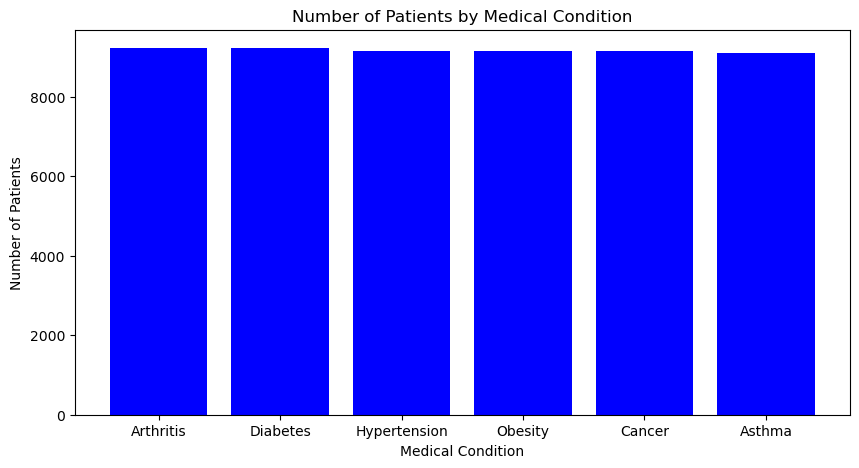

In [18]:
# visualization

plt.figure(figsize=(10, 5))
plt.bar(condition_count.index, condition_count.values, color='blue')
plt.title('Number of Patients by Medical Condition')
plt.xlabel('Medical Condition')
plt.ylabel('Number of Patients')
plt.show()

In [19]:
# using plotly
import plotly.express as px

fig = px.bar(x=condition_count.index, 
             y=condition_count.values,
             labels={'x': 'Medical Condition', 'y': 'Number of Patients'},
             title='Number of Patients by Medical Condition')

fig.update_layout(xaxis_tickangle=-45)
fig.show()


In [20]:
# Q2 - How is patients age distributed across the network ?
age_mean = df['Age'].mean()
age_mean

np.float64(51.53518538733035)

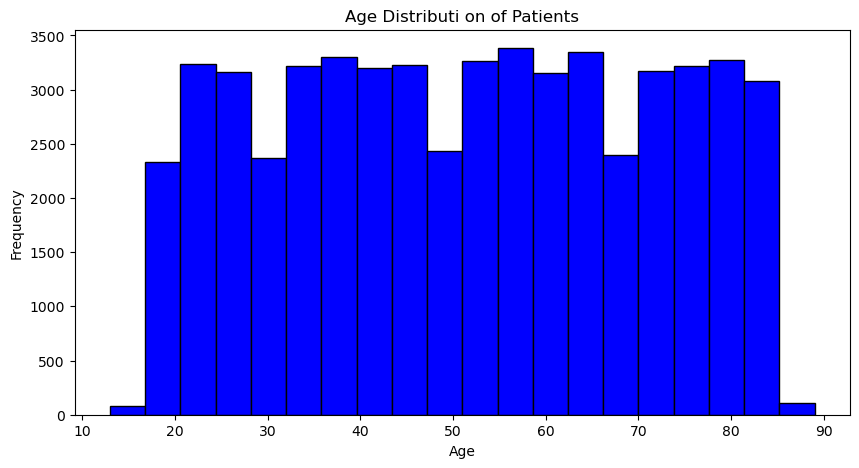

In [21]:
# visualization
plt.figure(figsize=(10, 5))
plt.hist(df['Age'], bins=20, color='blue',edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distributi on of Patients')
plt.show()


In [22]:
# Q3 - How has average treatment cost changed over the time
Avg_treatment_cost = df['Billing Amount'].mean()
print('Avg_treatment_cost: ', Avg_treatment_cost)

# Create a column for admission month
df['admission_month'] = df['Date of Admission'].dt.to_period('M')


Avg_treatment_cost:  25594.536589384963


In [23]:
Monthly_avg_cost = df.groupby('admission_month')['Billing Amount'].mean()
Monthly_avg_cost

admission_month
2019-05    25897.449683
2019-06    26324.004073
2019-07    25928.602375
2019-08    25457.102236
2019-09    24915.548929
               ...     
2024-01    25836.695757
2024-02    25703.588442
2024-03    25310.583412
2024-04    24930.033222
2024-05    25464.902913
Freq: M, Name: Billing Amount, Length: 61, dtype: float64

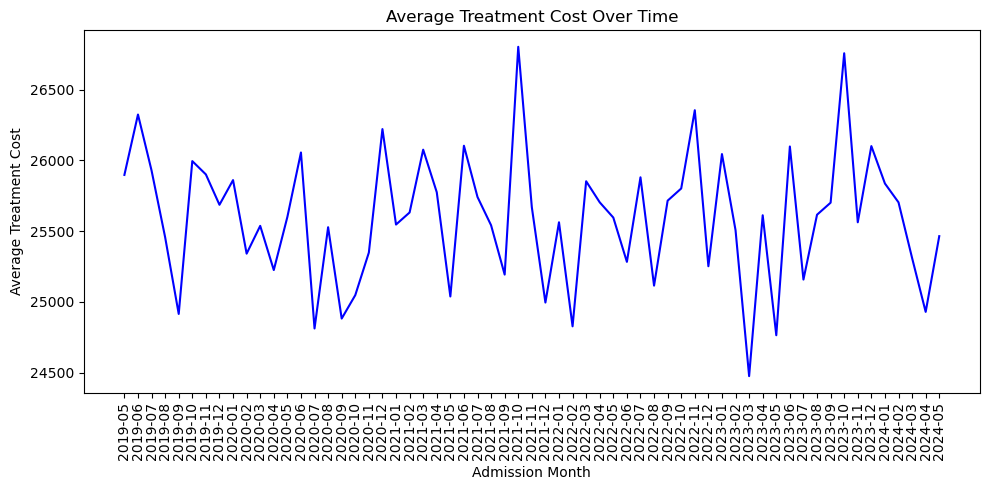

In [24]:
# visualization

plt.figure(figsize=(10, 5))
plt.plot(Monthly_avg_cost.index.astype(str), Monthly_avg_cost.values, color='blue')
plt.title('Average Treatment Cost Over Time')
plt.xlabel('Admission Month')
plt.ylabel('Average Treatment Cost')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [25]:
# using plotly
fig = px.line(x=Monthly_avg_cost.index.astype(str),
        y=Monthly_avg_cost.values, markers=True,
        labels={'x': 'Admission Month', 'y': 'Average Treatment Cost'},
        title='Average Treatment Cost Over Time')
fig.show()


In [26]:
# Q4 - Is there a relationship between Patients, Age and Treatment cost ?

senior_avg_cost = df.loc[df['Age'] >= 60, 'Billing Amount'].mean()
senior_avg_cost

np.float64(25563.587770925005)

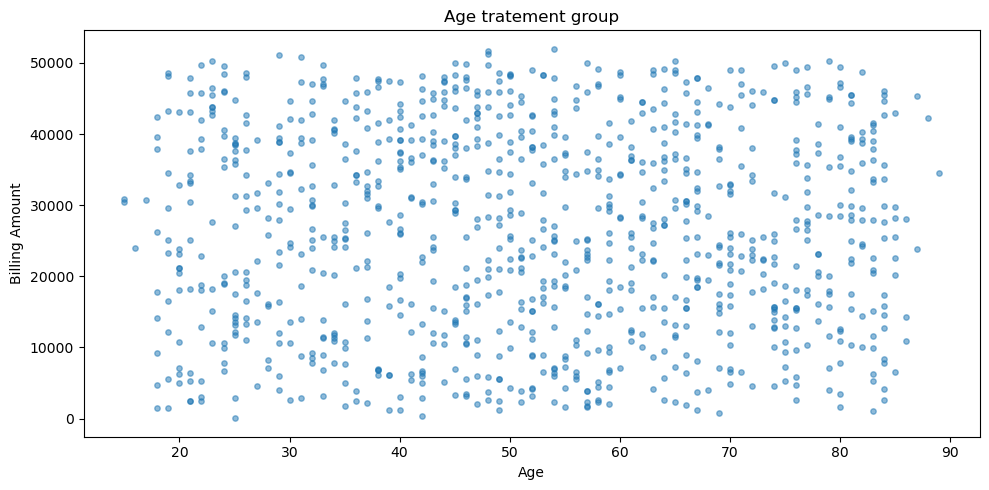

In [27]:
sample_df = df.sample(1000, random_state=1)

plt.figure(figsize=(10, 5))
plt.scatter(sample_df['Age'], sample_df['Billing Amount'], alpha=0.5, s=15)
plt.title('Age tratement group')
plt.xlabel('Age')
plt.ylabel('Billing Amount')
plt.tight_layout()
plt.show()

In [ ]:
# which insurance providers cover the most patients ?
insurance_provider = df['Insurance Provider'].value_counts()
insurance_provider


Insurance Provider
Cigna               11139
Medicare            11039
UnitedHealthcare    11014
Blue Cross          10952
Aetna               10822
Name: count, dtype: int64

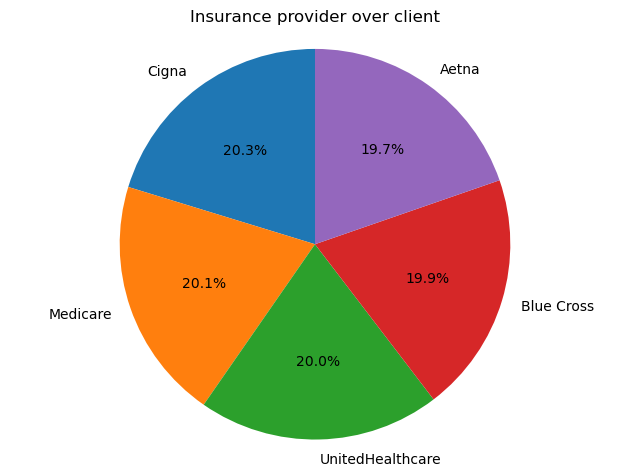

In [40]:
# visualization using plt
# plt.figure(figsize=(10, 5))
plt.pie(x=insurance_provider.values, 
        labels=insurance_provider.index,
        autopct='%1.1f%%',
        startangle=90)
plt.title('Insurance provider over client')
plt.tight_layout()
plt.axis('equal')
plt.show()

# visualization using Plotly

# --------- line chart
# fig = px.line(x=insurance_provider.index, 
#               y=insurance_provider.values,
#               markers=True,
#               labels={'x':'Insurance Provider', 'y':'client'},
#               title='insurance provider over client')
# fig.show()

# ------ Pie chart
# fig = px.pie(names=insurance_provider.index, labels=insurance_provider.values,
#              title='Patients by Insurance Provider', hole=0.3
#              )
# fig.show()

## Ad-Hoc business questions

In [80]:
# Q- Emergency department capacity planning:- how many emergency admission occured each month ?

emergency_dep = df[df['Admission Type'] == 'Emergency']
emergency_dep.groupby(df['Date of Admission'].dt.month).size()

# df[df['Admission Type'] == 'Emergency'].groupby(df['admission_month'].dt.month).size()


Date of Admission
1     1547
2     1452
3     1528
4     1473
5     1533
6     1483
7     1573
8     1533
9     1500
10    1490
11    1462
12    1528
dtype: int64

In [ ]:
# Q-2 Identify High-cost patient groups

# df.groupby('Medical Condition').agg(total_bill = ('Billing Amount' , 'sum'))
 
#                                                billing amount greater than 90 %
hight_patient_amount = df[df['Billing Amount'] > df['Billing Amount'].quantile(0.90)]
print('Total rows/patients: ',hight_patient_amount.shape[0])
hight_patient_amount


Total rows/patients:  5497


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Date of Discharge,days_stayed,admission_month
5,Emily Johnson,36,Male,A+,Asthma,2023-12-20,Taylor Newton,Nunez-Humphrey,UnitedHealthcare,48145.110951,389,Urgent,2023-12-24,Ibuprofen,Normal,2023-12-24,4,2023-12
7,Christina Martinez,20,Female,A+,Cancer,2021-12-28,Suzanne Thomas,"Powell Robinson and Valdez,",Cigna,45820.462722,277,Emergency,2022-01-07,Paracetamol,Inconclusive,2022-01-07,10,2021-12
8,Jasmine Aguilar,82,Male,AB+,Asthma,2020-07-01,Daniel Ferguson,Sons Rich and,Cigna,50119.222792,316,Elective,2020-07-14,Aspirin,Abnormal,2020-07-14,13,2020-07
30,Thomas Martinez,34,Male,B-,Asthma,2019-08-18,Jacob Huynh,Hart Ltd,Cigna,47909.128810,371,Urgent,2019-09-01,Ibuprofen,Inconclusive,2019-09-01,14,2019-08
35,David Anderson,25,Female,AB+,Asthma,2021-01-07,Emma Allison,Sons and Cox,Medicare,45453.418546,228,Elective,2021-01-26,Lipitor,Abnormal,2021-01-26,19,2021-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55446,Richard Moore,63,Female,B+,Hypertension,2021-11-17,Dr. Jacob Aguilar,Blevins Group,Aetna,47649.696638,304,Emergency,2021-12-09,Penicillin,Abnormal,2021-12-09,22,2021-11
55465,Amanda Stevens,71,Female,O-,Asthma,2019-06-11,Jessica Ramirez,Sims-Henderson,Cigna,45597.476264,164,Urgent,2019-06-22,Ibuprofen,Inconclusive,2019-06-22,11,2019-06
55467,Sandra Chen,62,Female,B+,Asthma,2022-06-03,Morgan Hess,Park Ltd,Aetna,48563.608920,269,Emergency,2022-06-06,Lipitor,Abnormal,2022-06-06,3,2022-06
55470,Taylor Best,60,Male,A-,Asthma,2020-10-14,Tracy Nichols,"Hopkins and Neal Logan,",Cigna,48664.879041,187,Emergency,2020-10-21,Penicillin,Normal,2020-10-21,7,2020-10


In [100]:
# 3- Flagging Emergency cases with Abnormal results for reviews

df[(df['Admission Type'] == 'Emergency') & (df['Test Results'] == 'Abnormal')]

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Date of Discharge,days_stayed,admission_month
12,Connor Hansen,75,Female,A+,Diabetes,2019-12-12,Kenneth Fletcher,"Powers Miller, and Flores",Cigna,43282.283358,134,Emergency,2019-12-28,Penicillin,Abnormal,2019-12-28,16,2019-12
27,Mr. Kenneth Moore,34,Female,A+,Diabetes,2022-06-21,James Ellis,Serrano-Dixon,UnitedHealthcare,18834.801341,157,Emergency,2022-06-30,Lipitor,Abnormal,2022-06-30,9,2022-06
38,Nicole Lucero,70,Female,O-,Diabetes,2022-03-12,Christine Johnson,"and Garcia Morris Cunningham,",Cigna,48290.693407,113,Emergency,2022-03-29,Lipitor,Abnormal,2022-03-29,17,2022-03
51,Stephanie Kent,42,Female,A-,Cancer,2019-06-15,Mary Moss,Beck-Galloway,Aetna,14681.016360,234,Emergency,2019-07-05,Ibuprofen,Abnormal,2019-07-05,20,2019-06
64,Nancy Glover,58,Male,A-,Hypertension,2020-05-08,Jennifer Larson,"Khan, and Rodriguez Fischer",Medicare,19183.168885,378,Emergency,2020-06-01,Aspirin,Abnormal,2020-06-01,24,2020-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55471,Ian Murphy,73,Female,B+,Hypertension,2023-05-03,Leslie Guerra,Lozano Ltd,Aetna,28397.377193,348,Emergency,2023-05-06,Lipitor,Abnormal,2023-05-06,3,2023-05
55480,Lauren Mills,33,Female,B-,Diabetes,2020-09-30,Mr. David Murray MD,"Riggs, King and Walls",Cigna,22375.523434,323,Emergency,2020-10-26,Aspirin,Abnormal,2020-10-26,26,2020-09
55488,Brittney York,43,Female,B-,Obesity,2024-02-02,Richard Matthews,Malone Ltd,Blue Cross,8128.932064,469,Emergency,2024-02-04,Aspirin,Abnormal,2024-02-04,2,2024-02
55490,Stephanie Oliver,82,Male,B-,Cancer,2022-01-10,Gary Leblanc,Group Lee,Cigna,17350.543524,381,Emergency,2022-01-21,Penicillin,Abnormal,2022-01-21,11,2022-01
